# HW04 降维、PCA 与 UMAP 分析

本 Notebook 按工作单任务 1–4 顺序组织所有分析代码。第一次运行前确认工作目录位于 hw04 项目目录；如缺少 UMAP 依赖，在 Notebook 单元运行 `%pip install umap-learn`，安装后重启内核。分析输出统一写入 `.tmp/dimension-reduction/student-results/`。

输入是 72 份白血病微阵列表达样本和 7,129 个探针。描述性 PCA/UMAP 使用全部样本，诊断仅用于拟合后的图形着色，不用于筛选特征或拟合降维器；该探索不能作为新样本预测评估。建模对照只使用源数据标记的 38 个训练样本，并将标准化、PCA 与分类器放入 Pipeline，在每个交叉验证训练折内拟合。

**可复现设置：**UMAP 随机种子 42，敏感性种子 7；交叉验证为 `StratifiedKFold(3, shuffle=True, random_state=42)`。所有描述图、表格和动态文字结论由下面各任务代码生成。

## 任务 1：降维目的、流程与预测评估

| 目的 | 需要的输出 | 如何判断是否有用 |
|---|---|---|
| 可视化 | 2D/3D 坐标图 | 可读性、参数稳定性及解释边界 |
| 去噪 | 降低不稳定变化的表示 | 重复测量或下游验证，不能只凭图更整齐 |
| 压缩特征 | 较少坐标及近似重建 | 维数、重建误差、解释率和计算成本 |
| 发现样本结构 | 候选分组、梯度和邻域 | 稳定性、外部信息及独立数据验证 |
| 后续建模输入 | 可一致转换新样本的表示 | 无泄露交叉验证和独立评估表现 |

**流程A（描述当前72份样本）：**表达矩阵 → 按探针标准化 → 全72行拟合PCA/UMAP → 拟合完成后按诊断着色。该图仅描述当前样本。

![描述性降维流程](figure2.svg)

**流程B（评估预测新样本）：**先固定训练/验证边界 → 在每个训练折内拟合标准化、PCA和分类器 → 将训练折拟合的变换应用到验证折并预测 → 仅以验证折评分 → 固定全部方案后才可评估未参与选择的测试集。

![训练折内拟合的预测评估流程](figure1.svg)

无监督 PCA 不使用诊断标签，但若在交叉验证前用全体样本拟合标准化或 PCA，验证折的特征分布和协方差结构已经影响变换方向，属于预处理信息泄露；它不是标签泄露。

## 任务 2：PCA 保留什么，又丢掉什么

下面先对全部72行进行描述性分析。探针列按 `StandardScaler` 做 z-score，随后进行 PCA；另以原始尺度作为对照。标准化不替代微阵列上游归一化，且可能放大低变异噪声。PC1 是使当前输入投影方差最大的单位方向，不等同于最能区分 ALL/AML 的方向，也不是某一个基因。权重按工作单定义为 `components_.T`。

环境版本： {'numpy': '1.26.4', 'pandas': '2.3.3', 'matplotlib': '3.10.6', 'scikit-learn': '1.6.1'}
数据形状与类别数： (72, 7129) {'ALL': 47, 'AML': 25}
标准化核查：


,max_abs_column_mean,max_abs_population_sd_minus_1
0,5.982869e-16,3.330669e-16


标准化 PCA 解释率： {'PC1': 0.14921586325599687, 'PC2': 0.09446172774145294, 'PC1+PC2': 0.2436775909974498, 'nonzero_components_upper_bound': 71}


,PC,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.149216,0.149216
1,PC2,0.094462,0.243678
2,PC3,0.046702,0.290380
3,PC4,0.040354,0.330734
4,PC5,0.034280,0.365014
5,PC6,0.031884,0.396898
6,PC7,0.027070,0.423968
7,PC8,0.024199,0.448167
8,PC9,0.022108,0.470274
9,PC10,0.021499,0.491773


PC1绝对权重最大的5个探针（方向权重，不是显著性或致病证据）：


,probe,PC1_direction_weight,absolute_weight
0,X92518_s_at,0.028786,0.028786
1,X95190_at,-0.028177,0.028177
2,X98253_at,0.027927,0.027927
3,X82895_at,0.027871,0.027871
4,Y09616_at,0.027757,0.027757


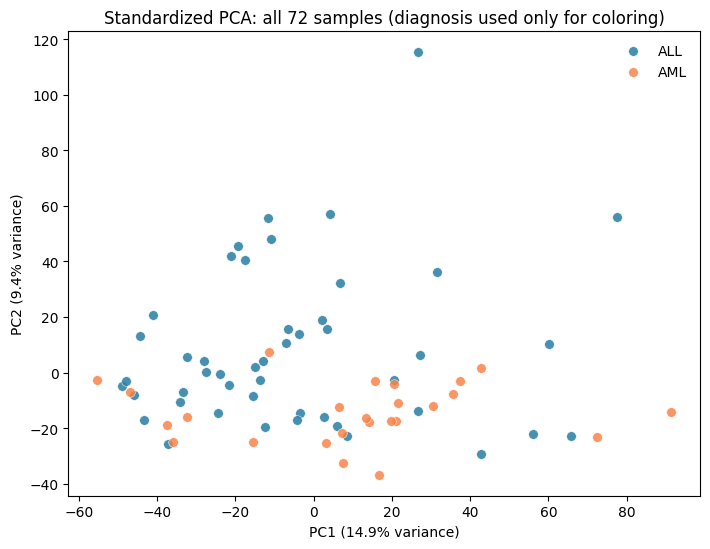

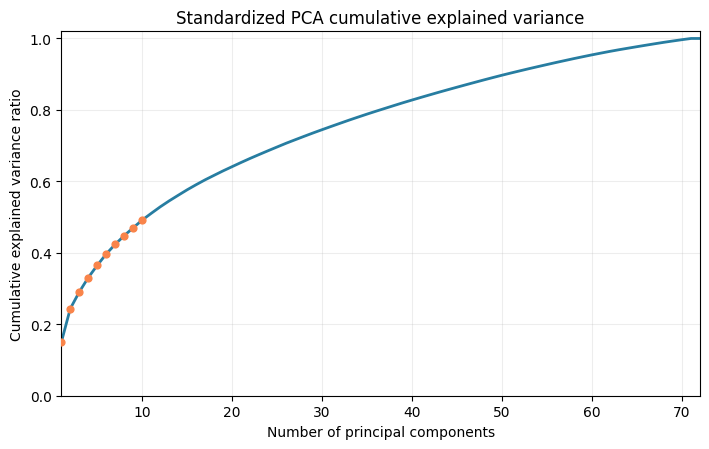

In [6]:
# Task 2: standardized descriptive PCA, figures, loadings, and sample-coordinate table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import sklearn
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

assert X_all.shape == (72, 7129), f"Unexpected shape: {X_all.shape}"
assert np.isfinite(X_all.to_numpy()).all(), "Input contains non-finite values"
assert df["diagnosis"].value_counts().to_dict() == {"ALL": 47, "AML": 25}

scaler_desc = StandardScaler()
Z = scaler_desc.fit_transform(X_all)  # descriptive only: all 72 rows
standardization_check = pd.DataFrame({
    "max_abs_column_mean": [np.abs(Z.mean(axis=0)).max()],
    "max_abs_population_sd_minus_1": [np.abs(Z.std(axis=0, ddof=0) - 1).max()],
})
print("环境版本：", {
    "numpy": np.__version__, "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__, "scikit-learn": sklearn.__version__,
})
print("数据形状与类别数：", X_all.shape, df["diagnosis"].value_counts().to_dict())
print("标准化核查：")
display(standardization_check)

pca_z = PCA(svd_solver="full")
scores_z = pca_z.fit_transform(Z)
evr_z = pca_z.explained_variance_ratio_
variance_table_z = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, len(evr_z) + 1)],
    "explained_variance_ratio": evr_z,
    "cumulative_explained_variance": np.cumsum(evr_z),
})
print("标准化 PCA 解释率：", {
    "PC1": evr_z[0], "PC2": evr_z[1], "PC1+PC2": evr_z[:2].sum(),
    "nonzero_components_upper_bound": min(X_all.shape[0] - 1, X_all.shape[1]),
})
display(variance_table_z.head(12))

weights_pc1 = pd.Series(pca_z.components_[0], index=feature_cols, name="PC1_direction_weight")
top5_pc1 = weights_pc1.loc[weights_pc1.abs().nlargest(5).index].rename_axis("probe").reset_index()
top5_pc1["absolute_weight"] = top5_pc1["PC1_direction_weight"].abs()
print("PC1绝对权重最大的5个探针（方向权重，不是显著性或致病证据）：")
display(top5_pc1)

pca_coordinates = pd.DataFrame({
    "sample_id": df["sample_id"], "original_split": df["original_split"],
    "diagnosis": df["diagnosis"], "PC1": scores_z[:, 0], "PC2": scores_z[:, 1],
})
pca_coordinates.to_csv(RESULTS_DIR / "task2_pca_sample_coordinates.csv", index=False)
variance_table_z.to_csv(RESULTS_DIR / "task2_standardized_pca_variance.csv", index=False)
top5_pc1.to_csv(RESULTS_DIR / "task2_pc1_top5_loadings.csv", index=False)

colors = {"ALL": "#277da1", "AML": "#f9844a"}
fig, ax = plt.subplots(figsize=(7.2, 5.6))
for label in ["ALL", "AML"]:
    mask = df["diagnosis"].eq(label).to_numpy()
    ax.scatter(scores_z[mask, 0], scores_z[mask, 1], s=48, alpha=.85,
               c=colors[label], label=label, edgecolors="white", linewidths=.4)
ax.set_xlabel(f"PC1 ({evr_z[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({evr_z[1]:.1%} variance)")
ax.set_title("Standardized PCA: all 72 samples (diagnosis used only for coloring)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "task2_pca_pc1_pc2.png", dpi=180, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.6))
pcs = np.arange(1, len(evr_z) + 1)
ax.plot(pcs, np.cumsum(evr_z), color="#277da1", linewidth=2)
ax.scatter(pcs[:10], np.cumsum(evr_z)[:10], color="#f9844a", s=24, zorder=3)
ax.set(xlabel="Number of principal components", ylabel="Cumulative explained variance ratio",
       title="Standardized PCA cumulative explained variance", xlim=(1, len(evr_z)), ylim=(0, 1.02))
ax.grid(alpha=.22)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "task2_pca_cumulative_variance.png", dpi=180, bbox_inches="tight")
plt.show()

In [7]:
# Task 2: centered-only/original-scale PCA comparison
pca_raw = PCA(svd_solver="full")  # PCA centers columns internally; no scale normalization
scores_raw = pca_raw.fit_transform(X_all)
evr_raw = pca_raw.explained_variance_ratio_
weights_raw_pc1 = pd.Series(pca_raw.components_[0], index=feature_cols, name="raw_PC1_direction_weight")

top_raw = weights_raw_pc1.loc[weights_raw_pc1.abs().nlargest(5).index].rename_axis("probe").reset_index()
top_raw["absolute_weight"] = top_raw["raw_PC1_direction_weight"].abs()
top_z = top5_pc1[["probe", "PC1_direction_weight", "absolute_weight"]].rename(columns={
    "PC1_direction_weight": "standardized_PC1_direction_weight",
    "absolute_weight": "standardized_absolute_weight",
})
top5_comparison = top_z.merge(top_raw.rename(columns={
    "raw_PC1_direction_weight": "centered_only_PC1_direction_weight",
    "absolute_weight": "centered_only_absolute_weight",
}), on="probe", how="outer")
variance_comparison = pd.DataFrame([
    {"input": "Standardized (z-score)", "PC1_ratio": evr_z[0], "PC2_ratio": evr_z[1], "PC1_PC2_sum": evr_z[:2].sum()},
    {"input": "Centered only (original scale)", "PC1_ratio": evr_raw[0], "PC2_ratio": evr_raw[1], "PC1_PC2_sum": evr_raw[:2].sum()},
])
print("解释率对照：")
display(variance_comparison)
print("标准化 PC1 前5权重探针与原尺度 PC1 对照（并集，未出现者表示不在该方案前5）：")
display(top5_comparison)

variance_comparison.to_csv(RESULTS_DIR / "task2_scale_comparison.csv", index=False)
top5_comparison.to_csv(RESULTS_DIR / "task2_top5_loading_scale_comparison.csv", index=False)
pd.DataFrame({
    "sample_id": df["sample_id"], "diagnosis": df["diagnosis"],
    "raw_PC1": scores_raw[:, 0], "raw_PC2": scores_raw[:, 1],
}).to_csv(RESULTS_DIR / "task2_centered_only_pca_coordinates.csv", index=False)

print(
    "解释：中心化后的72×7129矩阵秩至多为71，因此至多有71个非零主成分。",
    "整体同时翻转某个主成分的权重与得分只改变轴方向，不改变方差或样本间几何关系。",
    "标准化令各探针按自身变异尺度参与；原尺度下大方差探针可能主导方向，标准化则可能放大小变异噪声。",
    sep="\n",
)

解释率对照：


,input,PC1_ratio,PC2_ratio,PC1_PC2_sum
0,Standardized (z-score),0.149216,0.094462,0.243678
1,Centered only (original scale),0.174278,0.103386,0.277664


标准化 PC1 前5权重探针与原尺度 PC1 对照（并集，未出现者表示不在该方案前5）：


,probe,standardized_PC1_direction_weight,standardized_absolute_weight,centered_only_PC1_direction_weight,centered_only_absolute_weight
0,HG1428-HT1428_s_at,NaN,NaN,0.234867,0.234867
1,J04617_s_at,NaN,NaN,0.196253,0.196253
2,L06499_at,NaN,NaN,0.210453,0.210453
3,M25079_s_at,NaN,NaN,0.352388,0.352388
4,X82895_at,0.027871,0.027871,NaN,NaN
5,X92518_s_at,0.028786,0.028786,NaN,NaN
6,X95190_at,-0.028177,0.028177,NaN,NaN
7,X98253_at,0.027927,0.027927,NaN,NaN
8,Y09616_at,0.027757,0.027757,NaN,NaN
9,hum_alu_at,NaN,NaN,0.313552,0.313552


解释：中心化后的72×7129矩阵秩至多为71，因此至多有71个非零主成分。
整体同时翻转某个主成分的权重与得分只改变轴方向，不改变方差或样本间几何关系。
标准化令各探针按自身变异尺度参与；原尺度下大方差探针可能主导方向，标准化则可能放大小变异噪声。


回答：PC1 最大化的是什么方差？它是否等于“最能区分 ALL/AML 的方向”或某一个基因？主成分符号整体翻转是否改变结果？中心化后的 72 个样本为什么至多有 71 个非零主成分？
PC1最大化的是所有基因的方差，而不是“最能区分 ALL/AML 的方向”或某一个基因。主成分符号整体翻转不改变结果，中心化后72个样本至多有71个非零主成分是因为72维矩阵的秩最多为71。


## 任务 3：UMAP 参数与局部结构敏感性

同一标准化矩阵 `Z` 输入四次 UMAP；除指定参数外其余设置固定。诊断标签只在嵌入拟合完成后用于着色。邻域稳定性用每个样本的10近邻集合与基线的重合比例描述；它不是对全局几何、真实亚型或生物机制的验证。

| 比较维度 | PCA | UMAP |
|---|---|---|
| 线性/非线性 | 线性正交投影 | 非线性嵌入 |
| 主要保留信息 | 总方差最大的方向 | 由邻居数等设置影响的局部近邻结构 |
| 坐标轴含义 | 由输入特征线性组合定义 | UMAP1/UMAP2没有固定的特征或生物含义 |
| 方差解释率 | 可计算并报告 | 没有与PCA等价的方差解释率 |
| 局部/全局解释 | 线性投影中的距离也受截断维数影响 | 局部邻近可探索；岛屿间距离、面积、方向和密度不宜作定量生物解释 |
| 参数与随机性 | 受预处理、尺度和所保留成分数影响；符号可整体翻转 | 受`n_neighbors`、`min_dist`、度量、预处理和种子影响 |
| 用于预测时 | 每个训练折内拟合缩放器、PCA和模型 | 嵌入器及其前处理也只能在训练折拟合；不能用全样本探索后再宣称独立验证 |

c:\Users\史英琦godmin\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


umap-learn=0.5.12; fitted four embeddings on the same Z matrix, shape=(72, 7129)


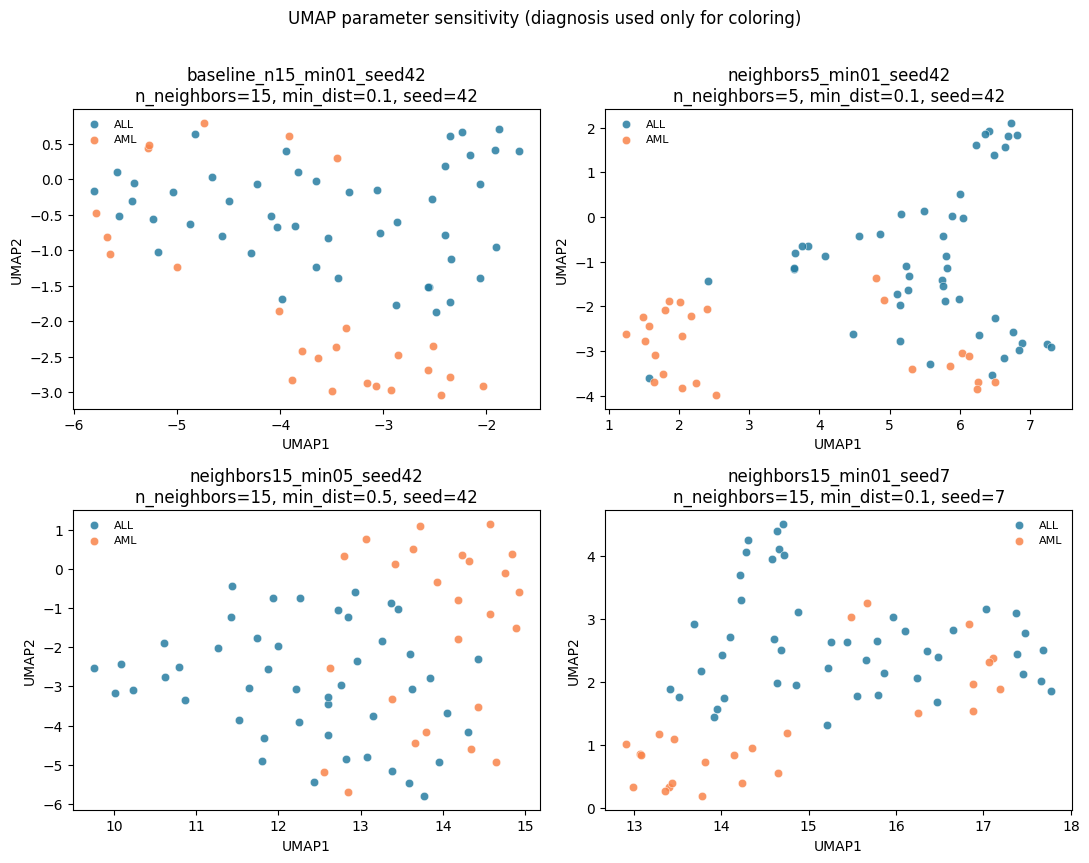

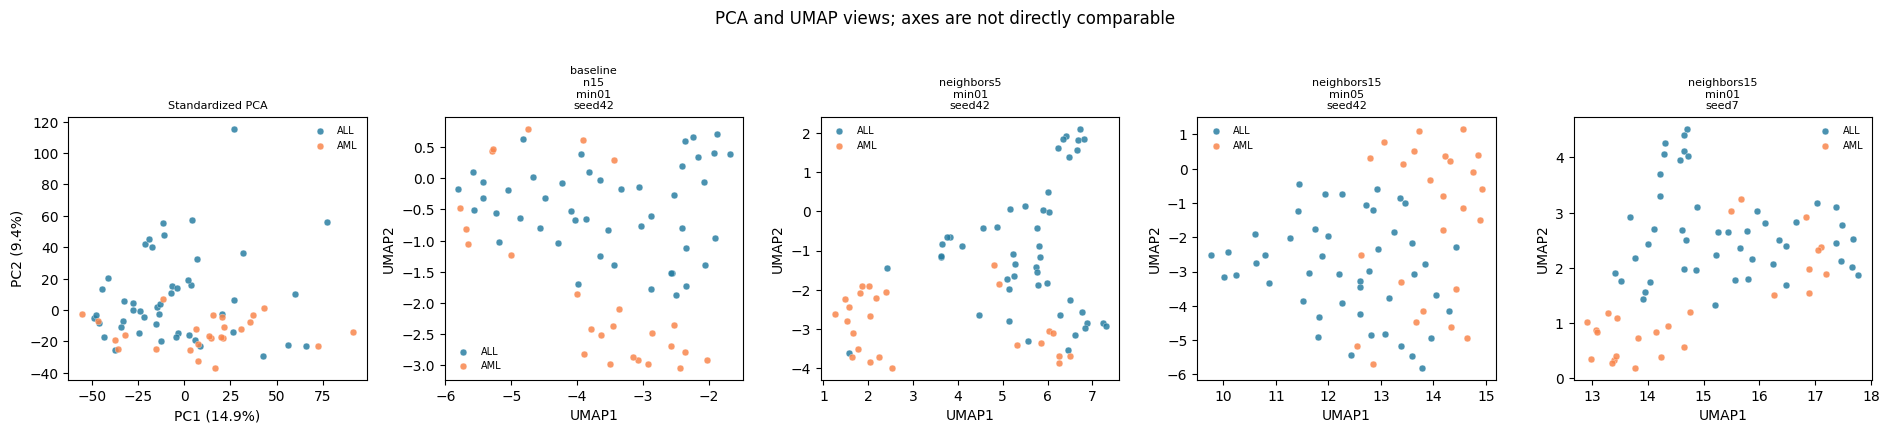

相对基线的10近邻重合：


,configuration,mean_10NN_overlap_vs_baseline,median_10NN_overlap_vs_baseline,fraction_samples_overlap_at_least_half
0,baseline_n15_min01_seed42,1.000000,1.0,1.000000
1,neighbors5_min01_seed42,0.626389,0.7,0.819444
2,neighbors15_min05_seed42,0.676389,0.7,0.916667
3,neighbors15_min01_seed7,0.733333,0.7,0.986111


解释边界：UMAP常用于单细胞或复杂表型的探索性展示，因为它侧重局部近邻；UMAP坐标轴没有固定生物学含义，也没有PCA式方差解释率。岛屿数量、岛屿间距离、面积、朝向和密度不能直接量化真实差异。缺少批次字段时，不能声称已排除批次影响。


In [4]:
# Task 3: UMAP baseline and one-factor-at-a-time sensitivity analysis
import umap
from umap import UMAP
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

umap_version = getattr(umap, "__version__", "unknown")
umap_configs = {
    "baseline_n15_min01_seed42": {"n_neighbors": 15, "min_dist": 0.1, "random_state": 42},
    "neighbors5_min01_seed42": {"n_neighbors": 5, "min_dist": 0.1, "random_state": 42},
    "neighbors15_min05_seed42": {"n_neighbors": 15, "min_dist": 0.5, "random_state": 42},
    "neighbors15_min01_seed7": {"n_neighbors": 15, "min_dist": 0.1, "random_state": 7},
}
umap_embeddings = {}
for name, params in umap_configs.items():
    reducer = UMAP(
        n_components=2,
        n_neighbors=params["n_neighbors"],
        min_dist=params["min_dist"],
        metric="euclidean",
        random_state=params["random_state"],
        n_jobs=1,
    )
    umap_embeddings[name] = reducer.fit_transform(Z)  # diagnosis is not passed to fit
print(f"umap-learn={umap_version}; fitted four embeddings on the same Z matrix, shape={Z.shape}")

coordinate_parts = [pca_coordinates.assign(method="PCA_standardized", configuration="all_72_descriptive")]
for name, coords in umap_embeddings.items():
    coordinate_parts.append(pd.DataFrame({
        "sample_id": df["sample_id"], "original_split": df["original_split"],
        "diagnosis": df["diagnosis"], "PC1": np.nan, "PC2": np.nan,
        "method": "UMAP", "configuration": name,
        "UMAP1": coords[:, 0], "UMAP2": coords[:, 1],
    }))
all_coordinates = pd.concat(coordinate_parts, ignore_index=True, sort=False)
all_coordinates.to_csv(RESULTS_DIR / "task3_pca_umap_coordinates_by_sample.csv", index=False)

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), sharex=False, sharey=False)
for ax, (name, coords) in zip(axes.flat, umap_embeddings.items()):
    for label in ["ALL", "AML"]:
        mask = df["diagnosis"].eq(label).to_numpy()
        ax.scatter(coords[mask, 0], coords[mask, 1], s=36, alpha=.85,
                   c=colors[label], label=label, edgecolors="white", linewidths=.35)
    params = umap_configs[name]
    ax.set_title(f"{name}\nn_neighbors={params['n_neighbors']}, min_dist={params['min_dist']}, seed={params['random_state']}")
    ax.set_xlabel("UMAP1")
    ax.set_ylabel("UMAP2")
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("UMAP parameter sensitivity (diagnosis used only for coloring)", y=1.01)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "task3_umap_parameter_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(19, 4.2))
plot_items = [("Standardized PCA", scores_z[:, :2], True)] + [
    (name, coords, False) for name, coords in umap_embeddings.items()
]
for ax, (title, coords, is_pca) in zip(axes, plot_items):
    for label in ["ALL", "AML"]:
        mask = df["diagnosis"].eq(label).to_numpy()
        ax.scatter(coords[mask, 0], coords[mask, 1], s=24, alpha=.84,
                   c=colors[label], label=label, edgecolors="white", linewidths=.25)
    if is_pca:
        ax.set_xlabel(f"PC1 ({evr_z[0]:.1%})")
        ax.set_ylabel(f"PC2 ({evr_z[1]:.1%})")
    else:
        ax.set_xlabel("UMAP1")
        ax.set_ylabel("UMAP2")
    ax.set_title(title.replace("_", "\n"), fontsize=8)
    ax.legend(frameon=False, fontsize=7)
fig.suptitle("PCA and UMAP views; axes are not directly comparable", y=1.02)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "task3_pca_umap_side_by_side.png", dpi=180, bbox_inches="tight")
plt.show()

# Compare each embedding's 10-neighbor sets with baseline, excluding each sample itself.
k = 10
neighbor_sets = {}
for name, coords in umap_embeddings.items():
    nn = NearestNeighbors(n_neighbors=k + 1, metric="euclidean").fit(coords)
    indices = nn.kneighbors(coords, return_distance=False)
    neighbor_sets[name] = [set(row[row != i][:k].tolist()) for i, row in enumerate(indices)]

baseline_name = "baseline_n15_min01_seed42"
stability_rows = []
for name, sets in neighbor_sets.items():
    sample_scores = [len(a & b) / k for a, b in zip(neighbor_sets[baseline_name], sets)]
    stability_rows.append({
        "configuration": name,
        "mean_10NN_overlap_vs_baseline": float(np.mean(sample_scores)),
        "median_10NN_overlap_vs_baseline": float(np.median(sample_scores)),
        "fraction_samples_overlap_at_least_half": float(np.mean(np.asarray(sample_scores) >= 0.5)),
    })
neighbor_stability = pd.DataFrame(stability_rows)
neighbor_stability.to_csv(RESULTS_DIR / "task3_umap_neighbor_stability.csv", index=False)
print("相对基线的10近邻重合：")
display(neighbor_stability)
print("解释边界：UMAP常用于单细胞或复杂表型的探索性展示，因为它侧重局部近邻；UMAP坐标轴没有固定生物学含义，也没有PCA式方差解释率。岛屿数量、岛屿间距离、面积、朝向和密度不能直接量化真实差异。缺少批次字段时，不能声称已排除批次影响。")

回答：
邻近关系方面，图中一些样本群在不同设置下仍可辨认，但整体布局变化很大。例如，基线与 n_neighbors=5 的图中，局部聚集的形态和位置已不同；min_dist=0.5 时点云更分散；随机种子改为7后，图形方向和布局也明显变化。因此，这张图支持“部分局部结构可能在设置变化时仍存在”的观察，但仅凭图无法确定具体哪些样本始终互为近邻；这需要用坐标计算各样本的近邻集合及重合率。
岛屿数量、岛屿间距离、方向和面积从图上看都不宜认为稳定。不同参数下嵌入的形状和空间布局发生明显变化，且UMAP坐标轴可以旋转、翻转或重排；图上岛屿之间的距离和面积也不代表原始高维空间中的真实生物学距离或群体规模。
UMAP常用于单细胞或复杂表型展示，是因为它能将高维数据中的局部邻域关系映射到二维，便于探索候选分组、连续梯度和异常样本。它适合提出假设，但不直接检验假设。
所以，图中UMAP的视觉分离不能证明疾病机制、真实亚型数量，也不能证明对新患者有预测能力。验证机制需要额外的生物学证据，判断亚型需稳定、可重复的聚类及独立样本支持，预测能力则需无信息泄露的训练验证流程和独立测试集。
最后，本数据缺少批次字段，因此不能宣称已经排除批次影响。诊断组间的分离可能与疾病状态有关，也可能部分来自未记录的批次、样本处理或测量流程差异；当前图无法区分这些解释。

## 任务 4：给研究团队的结论、退出卡与三道作业

现有记录中有标准化 PCA 的已运行结果：PC1 解释率为14.92%，PC2为9.45%，二者合计24.37%；PC1绝对权重最大的探针为X92518_s_at，方向权重约为0.02879。
结论

主张：二维PCA或UMAP图可以用于探索这72份白血病样本的表达结构，但图上出现分离本身不足以证明疾病机制、真实亚型数量或对新患者的预测能力。

证据：标准化PCA的PC1和PC2分别解释14.92%和9.45%的总方差，合计24.37%；PC1绝对权重最大的探针X92518_s_at的方向权重约为0.02879，而UMAP对照分别改变邻居数、最小距离和随机种子。

推理：PCA提取的是无监督的高方差线性方向，UMAP呈现的是受参数影响的局部邻域结构，因此只有在不同设置下仍可重复的邻近关系，才适合作为后续假设的线索。

边界：本分析缺少批次信息和独立验证队列，不能据此排除批次影响或推断临床泛化；下一步应结合批次及临床元数据，并在预先固定的流程中使用独立队列验证。

退出卡
我不接受“二维图分得开就证明发现了疾病机制并能预测新患者”的主张，因为降维图主要呈现特定变换下的样本结构，而非因果机制或预测效能。标准化PCA中，PC1解释14.92%的总方差，PC2解释9.45%；UMAP则通过基线设置及邻居数、最小距离和随机种子的单因素对照检查局部结构对参数变化的敏感性。若某些近邻关系在这些设置下保持稳定，它们可以支持提出可检验的结构假设，但不能单独确定疾病亚型或生物学机制。要把该假设提升为生物医学结论，仍需批次信息、独立样本和预先设定的验证分析；预测新患者的能力也必须通过无信息泄露的模型评估来检验。
三道作业
1. PCA第一主成分代表什么？
第一主成分是标准化后的7,129维探针表达向量的一个单位长度线性组合；它在所有线性投影方向中，使72份样本投影得分的方差最大。本次标准化PCA中，PC1解释总方差的14.92%。按本工作单将components_.T定义为方向权重的约定，X92518_s_at是PC1绝对权重最大的探针，其带符号权重约为0.02879。这表示该探针对PC1方向的线性组合有相对较大的系数，不表示它具有统计显著性、因果作用或单独区分ALL与AML的能力。整体翻转PC1权重与得分的符号只会改变坐标轴朝向，不改变其解释方差或样本间的结构关系。
2. 为什么PCA前通常需要考虑标准化？
PCA对特征的尺度和方差敏感。若各探针保留原始尺度，方差较大的特征可能在总方差中占据较大比重，从而主导主成分方向；按探针标准化后，各列以自身变异尺度参与分析，得到的方向更多反映特征之间的相对共变模式。代价是标准化可能提高低变异噪声的相对影响，因此不能仅因标准化后的解释率或图形看起来更理想，就认定它更适合所有研究问题。原尺度与标准化结果应作为敏感性对照，结合数据生成过程和研究目标解释。本数据包含负值，不应直接按原始RNA-seq计数处理或任意取对数；标准化也不能替代微阵列上游归一化或批次校正。当前没有原尺度PCA的实际运行结果，因此不报告其具体解释率或主导探针。
3. UMAP图能说明什么，不能说明什么？
UMAP可将高维数据中的局部近邻关系映射到二维空间，用于探索复杂结构并提出后续验证假设。本作业将基线设置为n_neighbors=15、min_dist=0.1、random_state=42，并分别将邻居数改为5、最小距离改为0.5、随机种子改为7，以单因素方式考察嵌入对设置的敏感性。比较时应依据同一样本近邻集合的重合情况讨论哪些局部关系相对稳定；岛屿数量、岛屿间距离、面积和方向不能直接当作真实生物学距离或亚型数量。UMAP坐标轴没有固定的基因或疾病含义，也不存在与PCA解释率相同的指标。由于这组参数对照尚未运行，我不对本次结果中哪些邻居实际稳定作出断言。即便图上显示诊断组分离，也不能据此证明疾病机制或新患者预测性能；当前数据没有批次字段，因此同样不能声称已排除批次影响。